# WP08 — Tahmin ve değerlendirme protokolü: karar öncesi inceleme

**Bu çalışmada eğitim veya performans sonucu yoktur.** ROADMAP WP08 split/baseline eğitimlerini içerir; son kullanıcı talimatı metodolojiyi önce gerekçelendirmeyi ve onay beklemeyi gerektirir. Burada 62 ilaç için seçenekler somutlaştırılır; D01–D07 onaylanmış sayılmaz.

Deney birimi ilaçtır; satır veya ilaç–PT çifti değildir. Aynı ilaçtan çok sayıda etiket olması bağımsız örneklem büyüklüğünü artırmaz. Önceki WPlarda tüm 62 ilaç etiketleri keşfedildiği için gelecekteki sonuçlar iç doğrulamadır; hiç görülmemiş prospektif test iddiası kurulamaz.

In [1]:
from pathlib import Path
import json,sys
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():ROOT=ROOT.parent
QA=ROOT/'reports/qa/WP08';FIG=ROOT/'reports/figures/WP08';FIG.mkdir(parents=True,exist_ok=True)
pd.set_option('display.max_rows',125);pd.set_option('display.max_columns',25);pd.set_option('display.max_colwidth',100)
def read(n):return pd.read_csv(QA/n,keep_default_na=False)
summary=json.loads((QA/'structure_audit_summary.json').read_text(encoding='utf-8'))
display(pd.DataFrame([summary]).drop(columns=['fingerprint','empty_scaffold_policy']))
display(pd.DataFrame([{'cohort':62,'test_bagimsiz_yeni_veri':False,'model_egitimi':False,'gercek_split':False,'nihai_yontem_onayi':False}]))

,cohort,pairwise_comparisons,full_identity_pairs,connectivity_pairs,nonstereo_pairs,same_nonempty_scaffold_pairs,empty_scaffold_drugs,WP04_review_preserved,salt_links_to_cohort,secondary_links_to_cohort,duplicate_cid_count,rdkit_version,no_parent_standardization,group_methods_are_proposals,actual_split_created,prior_files_verified
0,62,1891,0,1,1,34,0,8,99,63,0,2026.09.1,True,True,False,356


,cohort,test_bagimsiz_yeni_veri,model_egitimi,gercek_split,nihai_yontem_onayi
0,62,False,False,False,False


## 1. D01 — PT, tarihsel kategori ve klinik alt küme

Sıklık, “kaç ilaçta kaynakta pozitif kayıt var?” sorusunun yanıtıdır; hasta olay oranı değildir. Klinik alt küme uzman onaylı kavram listesi olmadan tanımlanamaz. Sayı daha yoğun görünsün diye PT veya kategori seçilmez.

,strategy,defined,classes,positive_pairs,positive_drugs,singleton_classes,classes_under5,support_min,support_max,median_positive_per_drug,target_approved,scope
0,PT_CUI,True,1061,6416,62,406,710,1,61,79.5,False,Full-cohort descriptive QA; never a train-selection result
1,historical_30,True,30,1011,61,0,0,7,61,16.5,False,Full-cohort descriptive QA; never a train-selection result
2,clinical_subset,False,not_defined,not_defined,not_defined,not_defined,not_defined,not_defined,not_defined,not_defined,False,No expert-approved target list; no post hoc subset invented


,strategy,class_id,positive_drugs_QA,denominator,observed_record_fraction_QA
322,PT_CUI,C0027497,61,62,0.983871
165,PT_CUI,C0015230,60,62,0.967742
498,PT_CUI,C0042963,59,62,0.951613
118,PT_CUI,C0011603,57,62,0.919355
127,PT_CUI,C0011991,55,62,0.887097
18,PT_CUI,C0002792,54,62,0.870968
236,PT_CUI,C0020517,53,62,0.854839
384,PT_CUI,C0033774,53,62,0.854839
487,PT_CUI,C0042109,52,62,0.838710
459,PT_CUI,C0040034,52,62,0.838710


,strategy,class_id,positive_drugs_QA,denominator,observed_record_fraction_QA
1070,historical_30,Hırıltı,7,62,0.112903
1073,historical_30,Karaciğer toksisitesi,9,62,0.145161
1090,historical_30,Şişkinlik,10,62,0.161290
1063,historical_30,Ağız mantarı,15,62,0.241935
1072,historical_30,Kalp hızlanması,15,62,0.241935
1087,historical_30,Vajinal mantar,17,62,0.274194
1076,historical_30,Kolit,18,62,0.290323
1066,historical_30,Bilinç kaybı,18,62,0.290323
1085,historical_30,Titreme,18,62,0.290323
1080,historical_30,Nefrotoksisite,20,62,0.322581


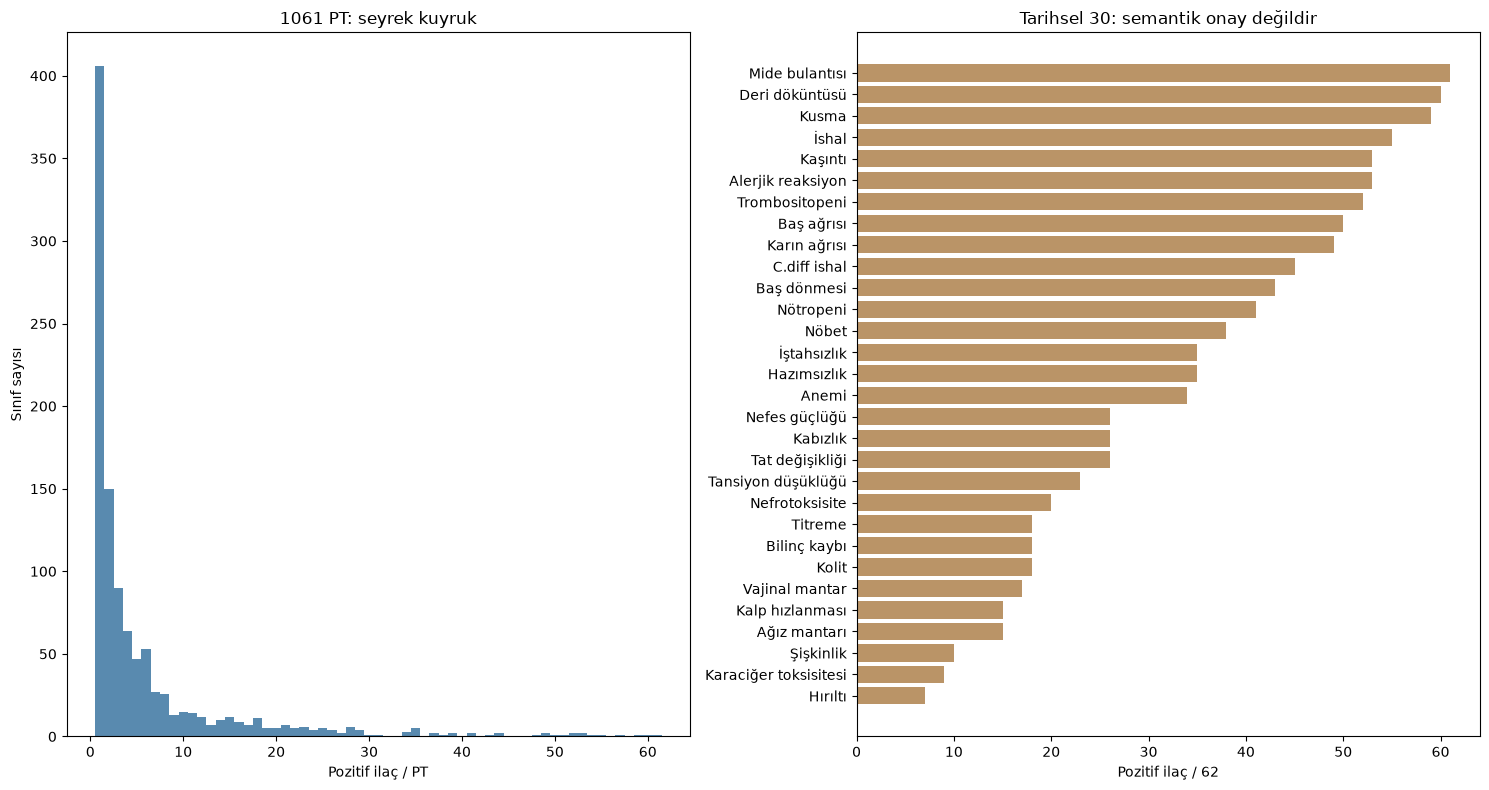

,kategori,kaynak_PT,CUI,pozitif_ilac_62,inceleme,clinical_expert_approved
0,Alerjik reaksiyon,Hypersensitivity,C0020517,53,yorumlayıcı çeviri,False
1,Anemi,Anaemia,C0002871,34,yüzeysel karşılık; klinik onay değil,False
2,Ağız mantarı,Oral candidiasis,C0006849,15,anlam genişletme riski,False
3,Baş ağrısı,Headache,C0018681,50,yüzeysel karşılık; klinik onay değil,False
4,Baş dönmesi,Dizziness,C0012833,43,yüzeysel karşılık; klinik onay değil,False
5,Bilinç kaybı,Loss of consciousness / Syncope,C0039070 / C0041657,18,birleştirme / ayrıntı kaybı,False
6,C.diff ishal,Clostridium difficile colitis / Pseudomembranous colitis,C0238106 / C1257843,45,birleştirme + neden özgüllüğü riski,False
7,Deri döküntüsü,Rash,C0015230,60,yüzeysel karşılık; klinik onay değil,False
8,Hazımsızlık,Dyspepsia,C0013395,35,yüzeysel karşılık; klinik onay değil,False
9,Hırıltı,Wheezing,C0043144,7,yüzeysel karşılık; klinik onay değil,False


In [2]:
options=read('label_options.csv');freq=read('class_frequencies_QA.csv');display(options)
pt=freq[freq.strategy.eq('PT_CUI')];cat=freq[freq.strategy.eq('historical_30')].sort_values('positive_drugs_QA')
display(pt.sort_values('positive_drugs_QA',ascending=False).head(12));display(cat)
fig,axs=plt.subplots(1,2,figsize=(15,8));axs[0].hist(pt.positive_drugs_QA,bins=np.arange(.5,62.5,1),color='#598aaf');axs[0].set(xlabel='Pozitif ilaç / PT',ylabel='Sınıf sayısı',title='1061 PT: seyrek kuyruk')
axs[1].barh(cat.class_id,cat.positive_drugs_QA,color='#ba9467');axs[1].set(xlabel='Pozitif ilaç / 62',title='Tarihsel 30: semantik onay değildir');plt.tight_layout();plt.savefig(FIG/'01_label_options.png',dpi=160);plt.show()
display(read('clinical_subset_review_queue.csv')[['kategori','kaynak_PT','CUI','pozitif_ilac_62','inceleme','clinical_expert_approved']])

**Yorum:** 1061 PT/6416 çift ile tarihsel 30/1011 çift farklı kavram uzaylarıdır. PT'de 406 sınıf tek ilaçta, 710 sınıf beşten az ilaçta görülür. Klinik alt küme sayısı **henüz tanımsızdır**; 30 kategorinin daha yoğun olması klinik doğruluğunu sağlamaz.

**Sızıntısız seçim yöntemi önerisi:** Etiket körü yapısal gruplar ve dış fold önce sabitlenir. Her dış train içinde PT destek eşiği ve grup desteği hesaplanır; iç validation yöntem ayarı içindir. Dış testin PT sıklığına bakılarak sınıf eklenmez/çıkarılmaz. 3/5/10 ilaç ve en az iki grup eşikleri yalnız onay bekleyen adaylardır; burada bu eşiklerle gerçek öğrenme sözlüğü üretilmedi. Uzman sabit klinik liste seçerse performansa bakılmadan gerekçesi kaydedilir. Testte train sözlüğü dışında pozitifler ayrı kapsanmayan hedef kapsamı olarak raporlanır.

## 2. D05 — Aynı yapı, stereo varyantı ve yakın yapı

Mevcut kaynak SMILES'lerden Morgan radius=2, 2048 bit ve stereo dışı Tanimoto benzerliği yalnız gruplama QA'sı için hesaplandı; yeni model özelliği değildir. Tam InChIKey ile bağlantı bloğu aynı şeyi anlatmaz. Murcko scaffold, kaynaktaki molekülün yerini almayan türetilmiş bir karşılaştırma temsilidir.

,drug_id1,drug_id2,morgan2_2048_no_stereo_tanimoto,name1,name2
1740,DB01137,DB01165,1.000000,Levofloxacin,Ofloxacin
49,DB00199,DB01211,0.922078,Erythromycin,Clarithromycin
247,DB00301,DB00485,0.901639,Flucloxacillin,Dicloxacillin
850,DB00493,DB01416,0.867647,Cefotaxime,Cefpodoxime
897,DB00512,DB04911,0.847682,Vancomycin,Oritavancin
493,DB00415,DB01060,0.840000,Ampicillin,Amoxicillin
908,DB00535,DB00671,0.794118,Cefdinir,Cefixime
777,DB00485,DB00713,0.786885,Dicloxacillin,Oxacillin
0,DB00199,DB00207,0.781609,Erythromycin,Azithromycin
1282,DB00684,DB01172,0.777778,Tobramycin,Kanamycin


,drug_id1,name1,drug_id2,name2,matching_representations,review_present
32,DB01137,Levofloxacin,DB01165,Ofloxacin,connectivity|nonstereo|murcko,True


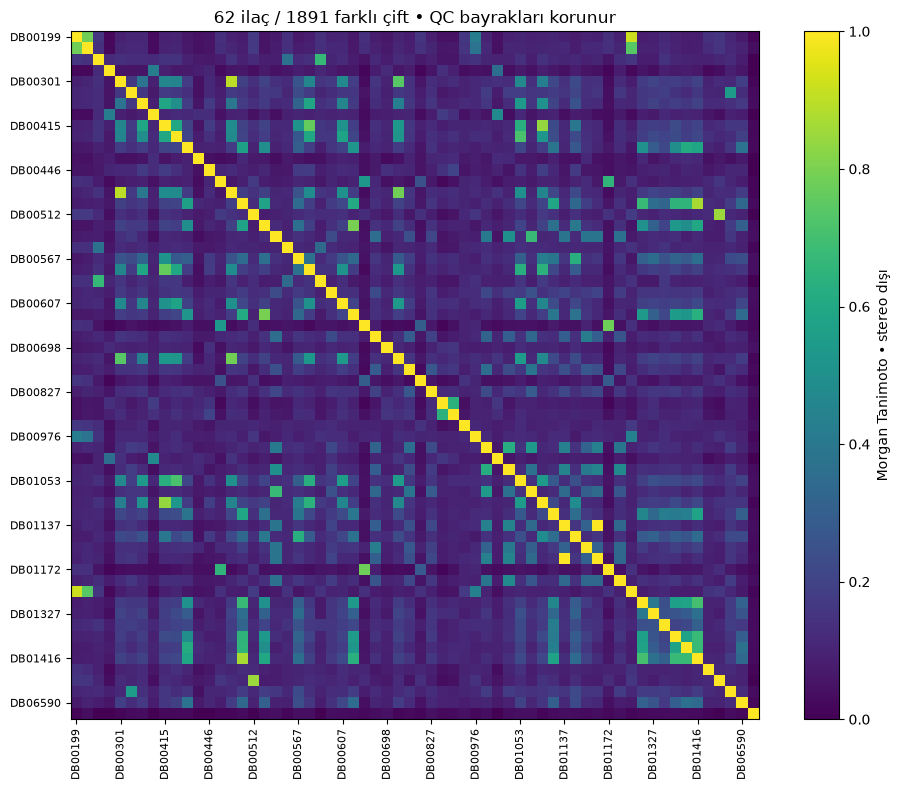

,drug_id,name,components,WP04_review,WP04_review_flags
0,DB00199,Erythromycin,1,False,
1,DB00207,Azithromycin,1,False,
2,DB00254,Doxycycline,1,False,
3,DB00259,Sulfanilamide,1,False,
4,DB00301,Flucloxacillin,1,False,
5,DB00303,Ertapenem,1,False,
6,DB00319,Piperacillin,1,False,
7,DB00359,Sulfadiazine,1,False,
8,DB00415,Ampicillin,1,False,
9,DB00417,Phenoxymethylpenicillin,1,False,


In [3]:
structures=read('structure_grouping_evidence.csv');pairs=read('pairwise_structure_similarity.csv');shared=read('shared_structure_pairs.csv')
names=structures.set_index('drug_id').name.to_dict();ordered=list(structures.drug_id)
top=pairs.nlargest(12,'morgan2_2048_no_stereo_tanimoto').copy();top['name1']=top.drug_id1.map(names);top['name2']=top.drug_id2.map(names);display(top)
display(shared[shared.matching_representations.str.contains('connectivity')])
sim=pd.DataFrame(np.eye(len(ordered)),index=ordered,columns=ordered)
for r in pairs.itertuples():sim.loc[r.drug_id1,r.drug_id2]=sim.loc[r.drug_id2,r.drug_id1]=r.morgan2_2048_no_stereo_tanimoto
fig,ax=plt.subplots(figsize=(10,8));im=ax.imshow(sim,vmin=0,vmax=1,cmap='viridis');ax.set_xticks(range(0,62,4),ordered[::4],rotation=90,fontsize=8);ax.set_yticks(range(0,62,4),ordered[::4],fontsize=8);fig.colorbar(im,ax=ax,label='Morgan Tanimoto • stereo dışı');ax.set_title('62 ilaç / 1891 farklı çift • QC bayrakları korunur');plt.tight_layout();plt.savefig(FIG/'02_structure_similarity.png',dpi=160);plt.show()
display(structures[['drug_id','name','components','WP04_review','WP04_review_flags']])

**Yorum:** Levofloxacin–Ofloxacin bağlantı bloğu ve nonisomeric yapı eşit; stereo dışı benzerlik 1'dir. Ayrı train/test ID'leri olarak bırakmak zor bir yeni-kimya testi sağlamaz. Bu kimyasal/klinik eşdeğerlik iddiası değildir. Tam yapı anahtarı veya CID tekrarı yok. 99 tuz–ebeveyn ve 63 ikincil–ebeveyn kaydı kaynak WP02'den korundu; tuzlar ayrı ilaç eklemedi. Bütün molekül ve QC bayrakları korundu, nötralizasyon/ana fragment seçimi/stereo tamamlama yapılmadı. Sekiz inceleme molekülünün gruplaması da bu nedenle geçicidir.

## 3. Gruplama seçenekleri ve yalnız büyüklük fizibilitesi

,method,groups,largest_group,singleton_groups,constraint_pairs,cohort,approved_for_split
0,primary_drug_only,62,1,62,0,62,False
1,connectivity_guard,61,2,60,1,62,False
2,scaffold_guard,41,5,29,34,62,False
3,similarity_0.7,49,3,40,15,62,False
4,similarity_0.8,56,2,50,6,62,False
5,similarity_0.9,59,2,56,3,62,False
6,scaffold_or_similarity_0.8,40,5,27,35,62,False


,method,hypothetical_k,fold_size_vector_only,min_fold_size,max_fold_size,largest_group,note
0,primary_drug_only,3,"[21, 21, 20]",20,21,1,Label-free size diagnostic; no drug-fold assignment saved
1,primary_drug_only,5,"[13, 13, 12, 12, 12]",12,13,1,Label-free size diagnostic; no drug-fold assignment saved
2,connectivity_guard,3,"[21, 21, 20]",20,21,2,Label-free size diagnostic; no drug-fold assignment saved
3,connectivity_guard,5,"[13, 13, 12, 12, 12]",12,13,2,Label-free size diagnostic; no drug-fold assignment saved
4,scaffold_guard,3,"[21, 21, 20]",20,21,5,Label-free size diagnostic; no drug-fold assignment saved
5,scaffold_guard,5,"[13, 13, 12, 12, 12]",12,13,5,Label-free size diagnostic; no drug-fold assignment saved
6,similarity_0.7,3,"[21, 21, 20]",20,21,3,Label-free size diagnostic; no drug-fold assignment saved
7,similarity_0.7,5,"[13, 13, 12, 12, 12]",12,13,3,Label-free size diagnostic; no drug-fold assignment saved
8,similarity_0.8,3,"[21, 21, 20]",20,21,2,Label-free size diagnostic; no drug-fold assignment saved
9,similarity_0.8,5,"[13, 13, 12, 12, 12]",12,13,2,Label-free size diagnostic; no drug-fold assignment saved


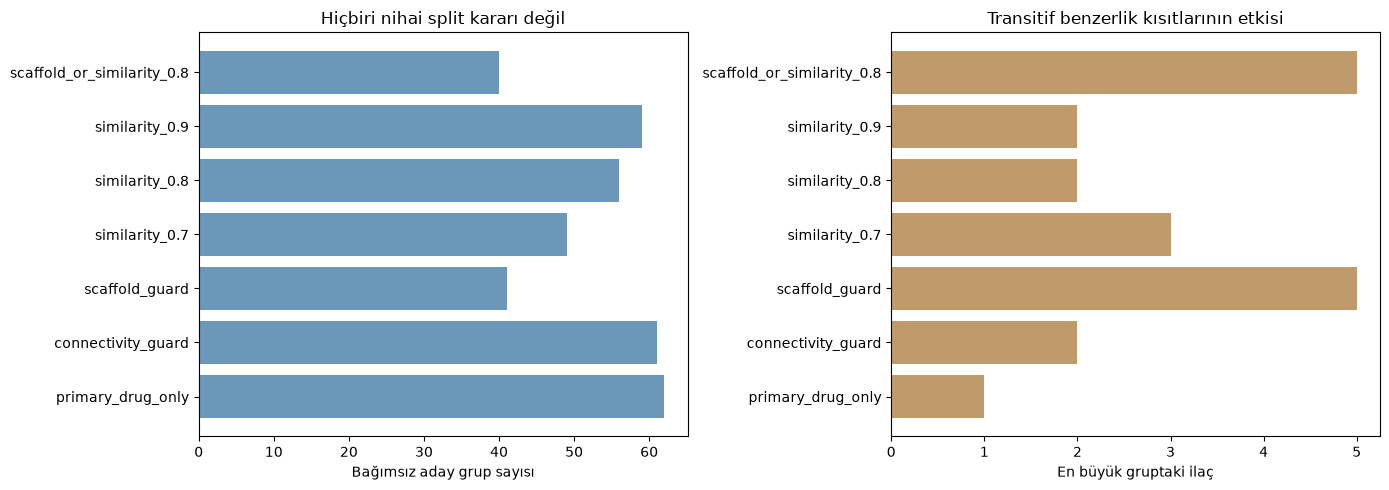

,drug_id1,name1,drug_id2,name2,matching_representations,review_present
0,DB00199,Erythromycin,DB01211,Clarithromycin,murcko,False
1,DB00254,Doxycycline,DB00560,Tigecycline,murcko,False
2,DB00254,Doxycycline,DB00595,Oxytetracycline,murcko,False
3,DB00259,Sulfanilamide,DB00446,Chloramphenicol,murcko,False
4,DB00301,Flucloxacillin,DB00485,Dicloxacillin,murcko,False
5,DB00301,Flucloxacillin,DB00713,Oxacillin,murcko,False
6,DB00415,Ampicillin,DB00578,Carbenicillin,murcko,True
7,DB00415,Ampicillin,DB01053,Benzylpenicillin,murcko,False
8,DB00415,Ampicillin,DB01060,Amoxicillin,murcko,False
9,DB00479,Amikacin,DB00684,Tobramycin,murcko,False


In [4]:
groups=read('group_summary.csv');sizes=read('split_size_feasibility.csv');display(groups);display(sizes)
fig,axs=plt.subplots(1,2,figsize=(14,5));axs[0].barh(groups.method,groups.groups,color='#6b98b8');axs[0].set(xlabel='Bağımsız aday grup sayısı',title='Hiçbiri nihai split kararı değil');axs[1].barh(groups.method,groups.largest_group,color='#bf9b6c');axs[1].set(xlabel='En büyük gruptaki ilaç',title='Transitif benzerlik kısıtlarının etkisi');plt.tight_layout();plt.savefig(FIG/'03_grouping_candidates.png',dpi=160);plt.show()
display(shared.head(12))

**Yorum:** Primary ID düzeyinde 62 grup; bağlantı kilidinde 61; scaffold kısıtında 41; scaffold veya benzerlik≥0,8 kısıtının birleşiminde 40 grup vardır. Sonuncunun en büyük grubu beş ilaçtır. 0,7/0,8/0,9 eşikleri biyolojik eşdeğerlik veya en iyi eşik değildir. Bağlı bileşenle gruplama transitiftir: uç üyeler doğrudan eşiğin altında olabilir. Aynı scaffold bazen yalnız basit fenil halkasıdır; Sulfanilamide/Chloramphenicol aynı scaffold görünürken genel kimyasal benzerlikleri düşük olabilir. Bu nedenle scaffold tek başına antibiyotik aile sınıflaması değildir.

Üç ve beş fold için tabloda görülen 21/21/20 ve 13/13/12/12/12 **yalnız grup büyüklüğü yerleştirme fizibilitesidir**. Gerçek ilaç–fold ataması, stratifikasyon veya test seçimi yapılmadı. Nested CV'de her dış train içinde iç grup ayrımı gerekir. 3 dış fold daha büyük test (~20–21) ama daha küçük train (~41–42); 5 dış fold daha büyük train (~49–50) ve daha küçük test (~12–13) verir. Bunlar fold sayısı önerisini somutlaştırır, onay yerine geçmez.

## 4. Seyrek sınıflar ilaç değil grup düzeyinde de sınır koyar

,strategy,method,classes,positive_in_one_group,at_least_3_positive_groups,at_least_5_positive_groups,interpretation
0,PT_CUI,connectivity_guard,1061,411,500,347,"Necessary support for each outer fold positive; not sufficient, not fold assignment"
1,PT_CUI,primary_drug_only,1061,406,505,351,"Necessary support for each outer fold positive; not sufficient, not fold assignment"
2,PT_CUI,scaffold_guard,1061,416,485,314,"Necessary support for each outer fold positive; not sufficient, not fold assignment"
3,PT_CUI,scaffold_or_similarity_0.8,1061,416,485,314,"Necessary support for each outer fold positive; not sufficient, not fold assignment"
4,PT_CUI,similarity_0.7,1061,415,497,344,"Necessary support for each outer fold positive; not sufficient, not fold assignment"
5,PT_CUI,similarity_0.8,1061,411,500,347,"Necessary support for each outer fold positive; not sufficient, not fold assignment"
6,PT_CUI,similarity_0.9,1061,411,500,347,"Necessary support for each outer fold positive; not sufficient, not fold assignment"
7,historical_30,connectivity_guard,30,0,30,30,"Necessary support for each outer fold positive; not sufficient, not fold assignment"
8,historical_30,primary_drug_only,30,0,30,30,"Necessary support for each outer fold positive; not sufficient, not fold assignment"
9,historical_30,scaffold_guard,30,0,30,30,"Necessary support for each outer fold positive; not sufficient, not fold assignment"


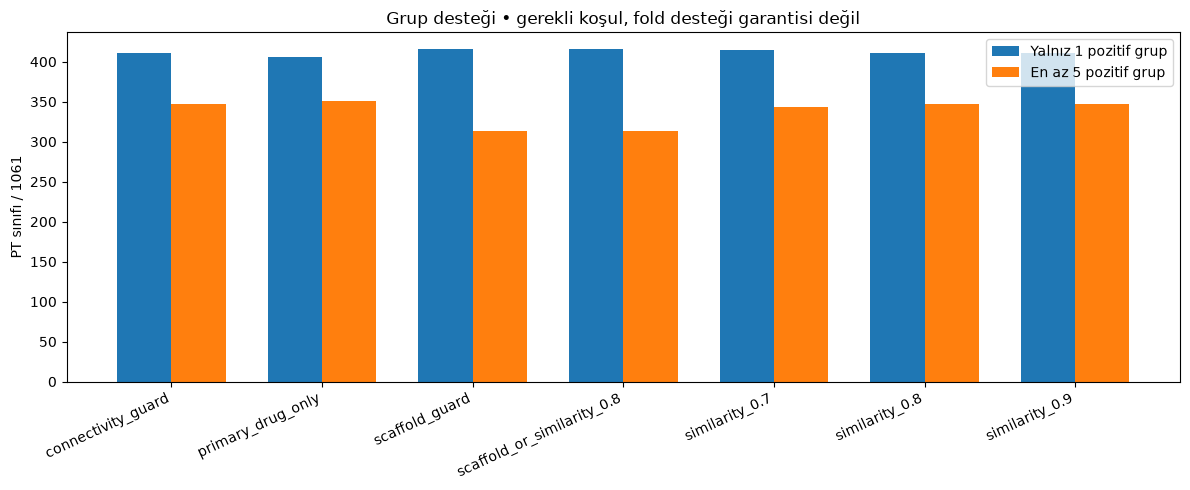

In [5]:
support=read('support_feasibility_QA.csv');display(support)
selected=support[support.strategy.eq('PT_CUI')]
fig,ax=plt.subplots(figsize=(12,5));x=np.arange(len(selected));ax.bar(x-.18,selected.positive_in_one_group,width=.36,label='Yalnız 1 pozitif grup');ax.bar(x+.18,selected.at_least_5_positive_groups,width=.36,label='En az 5 pozitif grup');ax.set_xticks(x,selected.method,rotation=25,ha='right');ax.set(ylabel='PT sınıfı / 1061',title='Grup desteği • gerekli koşul, fold desteği garantisi değil');ax.legend();plt.tight_layout();plt.savefig(FIG/'04_group_support_limits.png',dpi=160);plt.show()

**Yorum:** Connectivity kilidiyle 411, scaffold+0,8 varyantıyla 416 PT yalnız tek pozitif grupta kalır. Bu sınıflara hem eğitim hem bağımsız grup testinde pozitif garanti edilemez. Beş pozitif grup olması bile beş foldun her birine pozitif düşmesini garanti etmez. Bu global QA sayımları sınıf eşiği veya test seçmekte kullanılmamalıdır. Hesaplanamayan sınıf metriği NA ve gerekçesiyle gösterilmeli; başarım sıfırı gibi yazılmamalıdır.

## 5. D02 — 62 ilaçta modalite maskesi birincil aday

,drug_id,node_index,name,cid,chemistry_qc_available,molecule_review,protein_modality_available,review_flags,target_protein_count_QA,enzyme_protein_count_QA,transporter_protein_count_QA,carrier_protein_count_QA,human_strict_protein_count_QA,k12_scope_review_protein_count_QA
0,DB00199,0,Erythromycin,12560,True,False,True,,2,3,6,0,11,0
1,DB00207,1,Azithromycin,447043,True,False,True,,1,1,2,0,4,0
2,DB00254,2,Doxycycline,54671203,True,False,True,,0,1,2,1,4,0
3,DB00259,3,Sulfanilamide,5333,True,False,True,,1,0,0,0,0,1
4,DB00301,4,Flucloxacillin,21319,True,False,True,,1,1,1,0,2,0
5,DB00303,5,Ertapenem,150610,True,False,True,,8,1,0,1,2,6
6,DB00319,6,Piperacillin,43672,True,False,True,,4,0,2,0,2,0
7,DB00359,7,Sulfadiazine,5215,True,False,True,,2,3,0,0,3,1
8,DB00415,8,Ampicillin,6249,True,False,True,,7,0,4,1,5,0
9,DB00417,9,Phenoxymethylpenicillin,6869,True,False,True,,4,0,0,0,1,1


,chemistry_qc_available,protein_modality_available,drugs
0,False,False,1
1,False,True,7
2,True,False,1
3,True,True,53


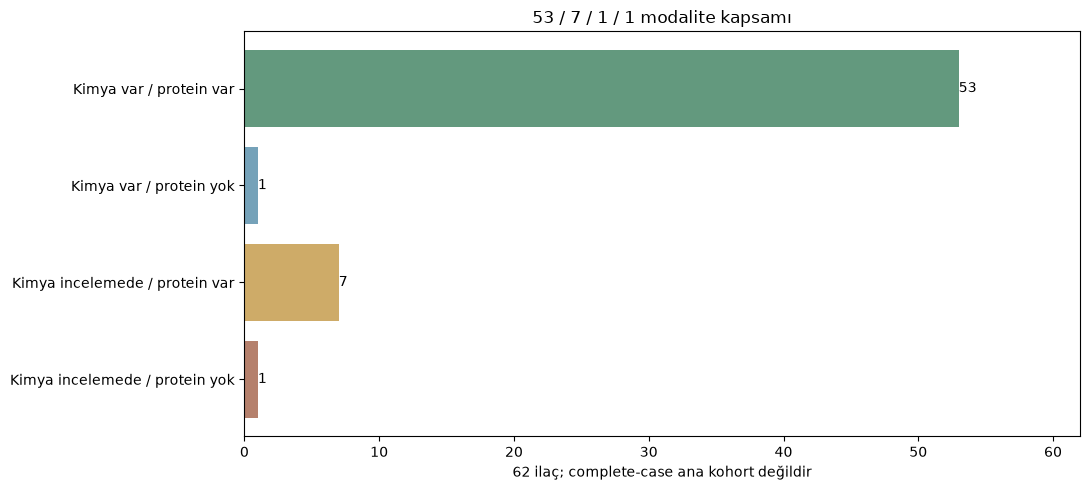

,drug_id,name,molecule_review,review_flags,protein_modality_available
21,DB00578,Carbenicillin,True,unspecified_atom_stereo,True
26,DB00684,Tobramycin,False,,False
31,DB00798,Gentamicin,True,multiple_components|unspecified_atom_stereo,True
37,DB00978,Lomefloxacin,True,unspecified_atom_stereo,True
39,DB01044,Gatifloxacin,True,unspecified_atom_stereo,True
45,DB01150,Cefprozil,True,unspecified_double_bond_stereo,True
46,DB01155,Gemifloxacin,True,unspecified_atom_stereo,True
47,DB01165,Ofloxacin,True,unspecified_atom_stereo,True
61,DB06799,Methenamine,True,unspecified_atom_stereo,False


In [6]:
m=read('drug_modality_QA_preserved.csv');display(m)
patterns=m.groupby(['chemistry_qc_available','protein_modality_available']).size().rename('drugs').reset_index();display(patterns)
fig,ax=plt.subplots(figsize=(11,5));labels=['Kimya '+('var' if r.chemistry_qc_available else 'incelemede')+' / protein '+('var' if r.protein_modality_available else 'yok') for r in patterns.itertuples()];bars=ax.barh(labels,patterns.drugs,color=['#b5806c','#ceab68','#75a2b9','#63997e']);ax.bar_label(bars);ax.set(xlabel='62 ilaç; complete-case ana kohort değildir',xlim=(0,62),title='53 / 7 / 1 / 1 modalite kapsamı');plt.tight_layout();plt.savefig(FIG/'05_modality_retention.png',dpi=160);plt.show()
display(m[m.molecule_review | ~m.protein_modality_available][['drug_id','name','molecule_review','review_flags','protein_modality_available']])

**Yorum:** 53 complete-case ilaç, 62'nin yerine geçirilmez. Maskeli dal yaklaşımı 62'yi korumaya adaydır. Tobramycin kimya dalıyla, protein modalitesi eksik olarak kalabilir. Methenamine'de hem temkinli kimya hem protein dalı kullanılamadığı için **etiketten bağımsız kişisel girdi bilgisi kalmayan bir durum** vardır: ayrı abstention veya yalnız train'den öğrenilen ortak önsel açıkça onaylanmalıdır. “62'yi koruduk” ifadesi 62'sine de kişiselleştirilmiş güvenilir tahmin verebildik demek değildir. Protein dizisi veya kimya uydurulmaz; ham değerle QC bypass edilmez.

## 6. D03–D04 — Context olmadan başlangıç ve ayrı PPI senaryosu

,network_taxid,graph_type,mapping_scope,threshold,nodes,edges,nonisolated_nodes,isolates,components,largest_component,density,mean_degree,mean_weighted_strength
0,9606,induced_seed,exact_taxon,700,63,184,51,12,14,49,0.094214,5.841270,4.991778
1,9606,expanded_context,exact_taxon,700,103,372,96,7,10,85,0.070817,7.223301,6.424097
2,511145,induced_seed,K12_parent_scope_review,700,23,68,21,2,4,12,0.268775,5.913043,5.615217
3,511145,expanded_context,K12_parent_scope_review,700,63,307,63,0,2,59,0.157194,9.746032,9.080095


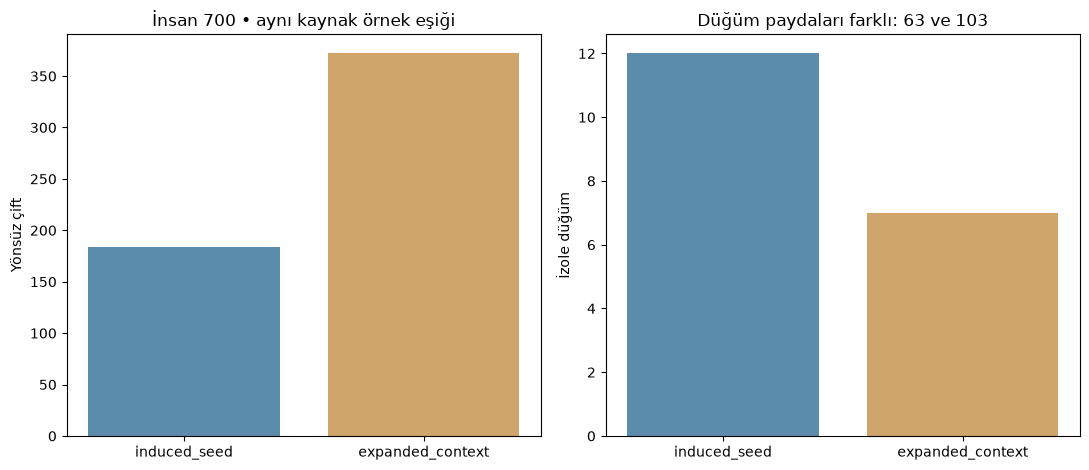

In [7]:
context=read('context_topology_cost_QA.csv');display(context)
human=context[context.network_taxid.astype(str).eq('9606')]
fig,axs=plt.subplots(1,2,figsize=(11,4.8));axs[0].bar(human.graph_type,human.edges,color=['#5c8cac','#d0a56c']);axs[0].set(ylabel='Yönsüz çift',title='İnsan 700 • aynı kaynak örnek eşiği');axs[1].bar(human.graph_type,human.isolates,color=['#5c8cac','#d0a56c']);axs[1].set(ylabel='İzole düğüm',title='Düğüm paydaları farklı: 63 ve 103');plt.tight_layout();plt.savefig(FIG/'06_context_topology_cost.png',dpi=160);plt.show()

**Yorum:** 80 context'in başlangıçtan çıkarılması doğrulanmış özellik gereksinimini korur; bazı yolları ve komşuları kaybettirir. İnsan 700 örneği 184 seed çifti/12 izole ile 372 geniş ağ çifti/7 izoleyi gösterir; bu bir model faydası ölçümü değildir ve 700'ü seçtirmez. WP08 B1/B2 PPI'sız adaylardır. Katı 63 insan proteiniyle PPI katkısı yalnız WP09'da gerçek encoder ve ablation ile sınanacaktır; 23 K12 inceleme proteini ana PPI ağına karışmaz. PPI'siz proteinler dizi modalitesinde kalır.

## 7. D06–D07 — Girdi, eğitim sınırı ve ölçüm anlamı

,entity,field,role,source,id_key,fit_scope,missing
0,drug,MW,candidate_numeric_input,reports/qa/WP04/chemical_features_clean.csv,id,training drug rows; nonmissing QC-approved values,8 held values remain missing; policy pending
1,drug,LogP,candidate_numeric_input,reports/qa/WP04/chemical_features_clean.csv,id,training drug rows; nonmissing QC-approved values,8 held values remain missing; policy pending
2,drug,HBD,candidate_numeric_input,reports/qa/WP04/chemical_features_clean.csv,id,training drug rows; nonmissing QC-approved values,8 held values remain missing; policy pending
3,drug,HBA,candidate_numeric_input,reports/qa/WP04/chemical_features_clean.csv,id,training drug rows; nonmissing QC-approved values,8 held values remain missing; policy pending
4,drug,TPSA,candidate_numeric_input,reports/qa/WP04/chemical_features_clean.csv,id,training drug rows; nonmissing QC-approved values,8 held values remain missing; policy pending
5,protein,length_aa,candidate_numeric_input,reports/qa/WP05/protein_features.csv,accession,unique training-linked accessions only,141 valid source proteins; no context features
6,protein,molecular_weight_Da,candidate_numeric_input,reports/qa/WP05/protein_features.csv,accession,unique training-linked accessions only,141 valid source proteins; no context features
7,protein,isoelectric_point,candidate_numeric_input,reports/qa/WP05/protein_features.csv,accession,unique training-linked accessions only,141 valid source proteins; no context features
8,protein,aromaticity_fraction,candidate_numeric_input,reports/qa/WP05/protein_features.csv,accession,unique training-linked accessions only,141 valid source proteins; no context features
9,protein,gravy_kyte_doolittle,candidate_numeric_input,reports/qa/WP05/protein_features.csv,accession,unique training-linked accessions only,141 valid source proteins; no context features


,metric_or_goal,assumption,meaning,limitation
0,Observed-label AP (micro/macro),"s=1 kayıt, s=0 unknown vekil karşılaştırma; onay olmadan hesaplanmaz",Kayıt varlığını sıralama; biyolojik pozitif precision veya klinik AUPRC değil,AP adım ağırlıklı özet; trapez PR alanıyla aynı tanım değil
1,Observed-label AUROC,Aynı proxy s varsayımı ve iki gözlenen sınıf gerekli,Rastgele gözlenen pozitifin unknown üstünde sıralanması; gerçek negatif özgüllüğü değil,Pozitif/unknown hiç yoksa sınıf metriği NA; sıfır başarı sayılmaz
2,Known-positive Recall@k / ranking,"Sabit k ve candidate sözlüğü, test pozitifleriyle tek son ölçüm",Bilinen pozitifleri yakalama; tüm gerçek yan etkilerin duyarlılığı değil,Eksik annotation recall ve ranking yorumunu sınırlar; k val içinde ayarlanır
3,PU-corrected ölçümler / nnPU loss,"Pozitif etiket hatası, class prior ve SCAR/SAR/propensity varsayımları açık",Varsayımlar geçerliyse gizli y hakkında çıkarım; burada doğrulanmış değil,Class prior 62 ilacın kayıt oranı değildir; önsel duyarlılığı gerekir
4,"Klinik kalibrasyon, özgüllük, bireysel risk",Temsili gerçek negatif ve olay/payda verisi gerektirir,Mevcut SIDER ilişkilerinden doğrulanamaz,Bu WP08 deneyi için hedeflenmez
5,CI / belirsizlik,Gelecekte ilaç veya yapısal grup düzeyinde örnekleme,Seçilmiş iç doğrulama örnekleminin belirsizliği,Çift düzeyi bootstrap bağımsızlık varsaymaz; CV fold skorları bağımsız örnek değildir


,decision_id,topic,recommended_candidate,pending_approval,reason_or_limit
0,D01,Etiket,Kaynak PT kimliğini koru; destek uygunluğunu her train içinde öğren; tarihsel 30 yalnız sabit ik...,3/5/10 ilaç ve >=2 grup eşikleri seçenek; nihai eşik/klinik alt küme onayı yok,Global QA frekansları train sözlüğü seçemez; dış fold etiketleri seçim dışında
1,D02,Eksik modalite,"62 ilaç, kaynak girdisinden maskeli dallar birincil aday; 53 complete-case yalnız duyarlılık",Gating/loss ve Methenamine fallback onayı gerekir,Gerçek AAC/MW eksikliği biyolojik sıfır değildir; tüm dallar yoksa train önseli veya abstain açı...
2,D03,Context,80 özelliksiz STRING context başlangıç modeline alınmasın,Kullanıcı tercihiyle uyumlu öneri; nihai eğitim henüz yok,"WP06 insan 700: seed 184 çift/12 izole, expanded 372/7; bağlantı kaybı model başarımı değildir"
3,D04,PPI,B1/B2 PPI yok; WP09 için yalnız katı insan PPI ayrı; K12 kapsamı ayrı beklesin,150/400/700/900 seçenek; en iyi eşik seçilmedi,PPI/no-PPI ancak WP09 forward kanıtından sonra; WP08 PPI eğitimi yok
4,D05,Bölme,Etiket körü connectivity kilidi; yapı-gruplu nested CV birincil aday; scaffold+benzerlik stres v...,Dış 3 veya 5 fold / iç 3 seçenekleri; scaffold vs identity genelleme hedefi onay bekler,"40 gruplu scaffold+0.8 aday; 62 zaten keşfedilmiş ilaçta iç doğrulama, bağımsız yeni test değil"
5,D06,Giriş,"v0.1 taslak: 5 kimya, 56 dizi, 4 rol ayrı, kaynak kimlikleri metadata; input maskeleri",ATC isteğe bağlı yol haritası varyantı; encode seviyesi/train vocab onayı gerekir,Train-only kimya scaler; protein scaler yalnız train-linked benzersiz accession; ID/PT/QA skorla...
6,D07,PU ve metrik,Gözlenen kayıt ilişkisi sıralaması ile biyolojik risk tahminini ayır; unknown bilimsel negatif d...,PU varsayımı/önsel belirsiz; proxy AP/AUROC ayrı onay gerektirir,SCAR/etiketlenme eğilimi SIDER için doğrulanmadı; klinik kalibrasyon/özgüllük iddiası yok


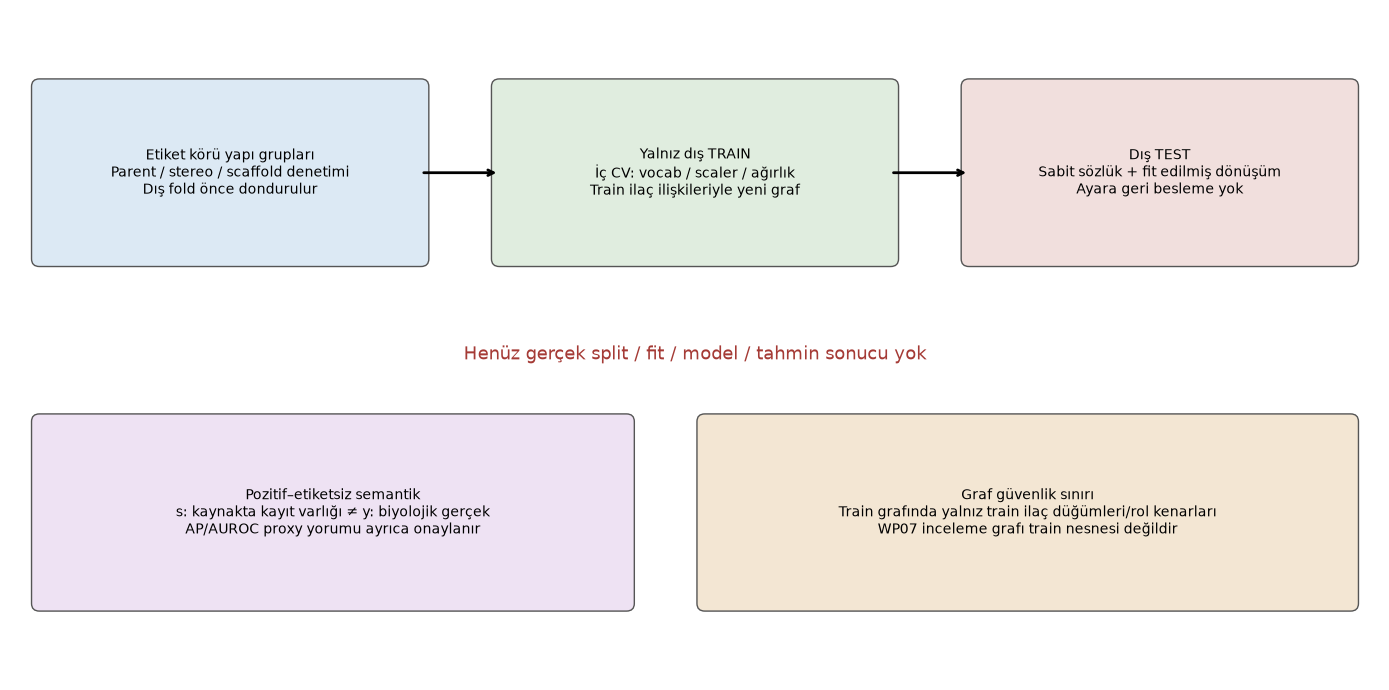

In [8]:
display(read('input_fields_v0_1_DRAFT.csv'));display(read('metric_interpretation.csv'));display(read('decision_proposals.csv'))
fig,ax=plt.subplots(figsize=(14,7));ax.set(xlim=(0,14),ylim=(0,7));ax.axis('off')
def box(x,y,w,h,text,color):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=.08',facecolor=color,edgecolor='#555'));ax.text(x+w/2,y+h/2,text,ha='center',va='center',fontsize=10)
box(.3,4.4,3.9,1.8,'Etiket körü yapı grupları\nParent / stereo / scaffold denetimi\nDış fold önce dondurulur','#dce9f4')
box(5,4.4,4,1.8,'Yalnız dış TRAIN\nİç CV: vocab / scaler / ağırlık\nTrain ilaç ilişkileriyle yeni graf','#e0eddf')
box(9.8,4.4,3.9,1.8,'Dış TEST\nSabit sözlük + fit edilmiş dönüşüm\nAyara geri besleme yok','#f1dfdd')
box(.3,.8,6,1.9,'Pozitif–etiketsiz semantik\ns: kaynakta kayıt varlığı ≠ y: biyolojik gerçek\nAP/AUROC proxy yorumu ayrıca onaylanır','#eee2f3')
box(7.1,.8,6.6,1.9,'Graf güvenlik sınırı\nTrain grafında yalnız train ilaç düğümleri/rol kenarları\nWP07 inceleme grafı train nesnesi değildir','#f3e6d3')
for a,b in [((4.2,5.3),(5,5.3)),((9,5.3),(9.8,5.3))]:ax.annotate('',xy=b,xytext=a,arrowprops=dict(arrowstyle='->',lw=2))
ax.text(7,3.35,'Henüz gerçek split / fit / model / tahmin sonucu yok',ha='center',fontsize=13,color='#a53b36')
plt.tight_layout();plt.savefig(FIG/'07_protocol_boundary.png',dpi=160);plt.show()

**Yorum:** Taslakta 5 kimya + 56 dizi alanı vardır; dört rol ayrı tutulur, kaynak ID'ler yalnız metadata/join içindir. Protein scaler'ının yalnız train-linked benzersiz accession'larda fit edilmesi, test ilacı bağlantılarının dolaylı dağılım etkisini önler. 141 proteinlik registry zaten kohort kaynaklıdır; onu sabit harici evren gibi kullanmak saf indüktif değerlendirme sayılmamalıdır. Yeni graph üreticisi bu iki kapsamı açık parametreyle ayırır, varsayılan karar vermez.

SIDER için `s=1` kaydı gözlenir; gizli biyolojik `y` ve etiketlenme eğilimi bilinmez. Unknown=0 ile AP/AUROC ancak kayıt sıralama proxy'sidir. Gerçek negatif, klinik kalibrasyon veya nedensellik iddiası olmaz. PU düzeltmesi için sınıf önseli ve SCAR/SAR gibi varsayımlar gerekir; burada doğrulanmadılar. Ortalama precision (AP), trapez PR eğrisi alanıyla aynı hesap değildir; ileride metrik adı/yöntemi açık yazılmalı. Belirsizlik ilaç/yapısal grup düzeyinde ele alınmalı, çiftler bağımsız sayılmamalıdır.

## 8. İnteraktif yapı benzerliği ve karar kapısı

In [9]:
import plotly.graph_objects as go
hover=np.array([[a+' '+names[a]+' ↔ '+b+' '+names[b] for b in ordered] for a in ordered])
fig=go.Figure(go.Heatmap(z=sim.to_numpy(),x=ordered,y=ordered,text=hover,hovertemplate='%{text}<br>Morgan stereo dışı Tanimoto: %{z:.3f}<extra></extra>',zmin=0,zmax=1,colorscale='Viridis'))
fig.update_layout(title='62 kaynak molekül • yalnız gruplama QA; yapı/QC eşdeğerliği iddiası yok',width=1100,height=1000)
fig.write_html(FIG/'structure_similarity_interactive.html',include_plotlyjs=True,full_html=True)
display(pd.DataFrame([{'kod_hucresi':9,'PNG':7,'interaktif_HTML':1,'canli_tarayici_testi':False,'metodoloji_onayi':'BEKLENİYOR','egitim':'YOK'}]))

,kod_hucresi,PNG,interaktif_HTML,canli_tarayici_testi,metodoloji_onayi,egitim
0,9,7,1,False,BEKLENİYOR,YOK


**Kapanış:** D01–D07 önerileri [WP08 karar kapısında](../reports/WP08_PROTOCOL_DECISION_GATE.md), gerçek sayımlar/testler [WP08 raporundadır](../reports/WP08.md). Başlangıç eğitimine onay verilmeden LR/RF/MLP veya PU modeli eğitilmez. WP09 çalışması başlamadı; forward komşuluk testi ve PPI/no-PPI/karıştırılmış PPI ablation gereksinimi korunur.

Yöntem kaynakları: [RDKit Morgan generator](https://www.rdkit.org/docs/source/rdkit.Chem.rdFingerprintGenerator.html), [Murcko scaffold](https://rdkit.org/docs/source/rdkit.Chem.Scaffolds.MurckoScaffold.html), [GroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupKFold.html), [sızıntı sınırları](https://scikit-learn.org/stable/common_pitfalls), [PU ölçüm düzeltme çalışması](https://arxiv.org/abs/1702.00518). Bunlar yöntem belgesidir; yeni biyolojik kaynak eklenmedi.